In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load Breast Cancer Dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

# Create target column
# 0 = Malignant, 1 = Benign
df['diagnosis'] = data.target

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [ ]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
0

Duplicate Records:
0


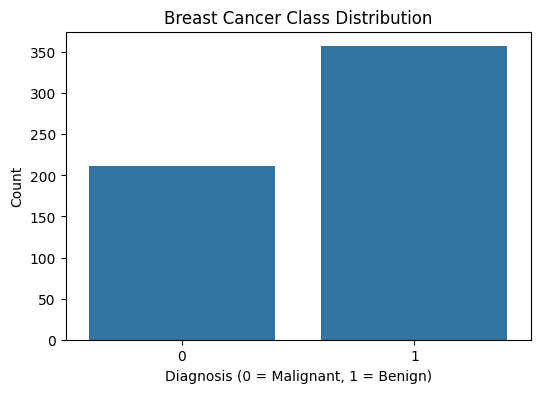

diagnosis
1    357
0    212
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x='diagnosis', data=df)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Diagnosis (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")

plt.show()

print(df['diagnosis'].value_counts())

In [ ]:
# Input features
X = df.drop('diagnosis', axis=1)

# Target variable
y = (df['diagnosis'] == 0).astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\n0 = Benign / Negative")
print("1 = Malignant / Positive")

Features shape: (569, 30)
Target shape: (569,)

Target Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

0 = Benign / Negative
1 = Malignant / Positive


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data: (455, 30)
Testing Data: (114, 30)

Training Class Distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing Class Distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


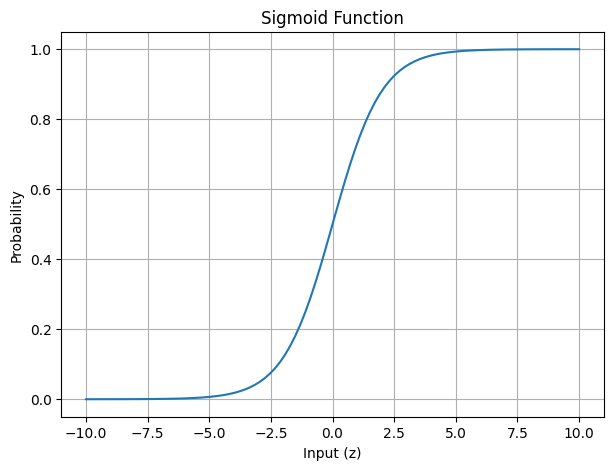

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 100)

probability = sigmoid(z)

plt.figure(figsize=(7,5))

plt.plot(z, probability)

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")

plt.grid()
plt.show()

In [ ]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [ ]:
print("Intercept:")
print(model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print("\nModel Coefficients:")
print(coefficients)

Intercept:
[-0.24300533]

Model Coefficients:
                    Feature  Coefficient
0               mean radius     0.361150
1              mean texture     0.482219
2            mean perimeter     0.353160
3                 mean area     0.439950
4           mean smoothness     0.350622
5          mean compactness    -0.439546
6            mean concavity     0.782298
7       mean concave points     0.952813
8             mean symmetry    -0.163991
9    mean fractal dimension    -0.080865
10             radius error     1.233325
11            texture error    -0.407611
12          perimeter error     0.748295
13               area error     0.909029
14         smoothness error     0.247991
15        compactness error    -0.906925
16          concavity error    -0.092341
17     concave points error     0.482089
18           symmetry error    -0.330658
19  fractal dimension error    -0.593876
20             worst radius     0.896968
21            worst texture     1.434093
22         

In [ ]:
 y_prob = model.predict_proba(X_test_scaled)[:, 1]

y_pred = model.predict(X_test_scaled)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted Probability': y_prob,
    'Predicted Class': y_pred
})

print(results.head(10))

   Actual  Predicted Probability  Predicted Class
0       0               0.000365                0
1       1               1.000000                1
2       0               0.042568                0
3       1               0.576187                1
4       0               0.509155                1
5       0               0.000616                0
6       1               0.761534                1
7       0               0.001012                0
8       0               0.000569                0
9       0               0.010768                0


Confusion Matrix:
[[71  1]
 [ 3 39]]

True Negative: 71
False Positive: 1
False Negative: 3
True Positive: 39


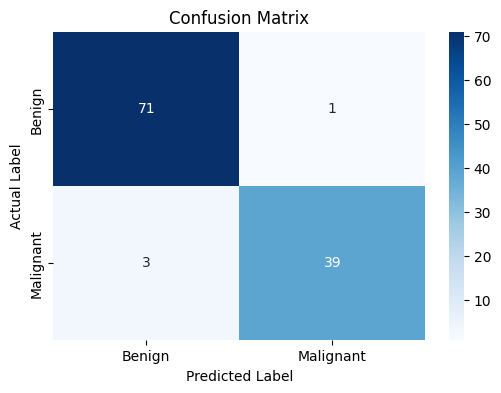

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

specificity = tn / (tn + fp)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
Specificity: 0.9861111111111112
F1 Score: 0.9512195121951219
ROC-AUC: 0.996031746031746


In [ ]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [ ]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train_scaled, y_train)

baseline_pred = baseline.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

model_accuracy = accuracy_score(y_test, y_pred)

print("Majority Class Baseline Accuracy:", baseline_accuracy)

print("Logistic Regression Accuracy:", model_accuracy)

Majority Class Baseline Accuracy: 0.631578947368421
Logistic Regression Accuracy: 0.9649122807017544


In [ ]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:

    pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_test, pred)

    precision = precision_score(y_test, pred, zero_division=0)

    recall = recall_score(y_test, pred, zero_division=0)

    f1 = f1_score(y_test, pred, zero_division=0)

    predicted_positive = np.sum(pred == 1)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted Positive': predicted_positive,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Predicted Positive  Accuracy  Precision    Recall  F1 Score
0        0.3                  42  0.982456    0.97619  0.976190   0.97619
1        0.5                  40  0.964912    0.97500  0.928571   0.95122
2        0.7                  38  0.964912    1.00000  0.904762   0.95000


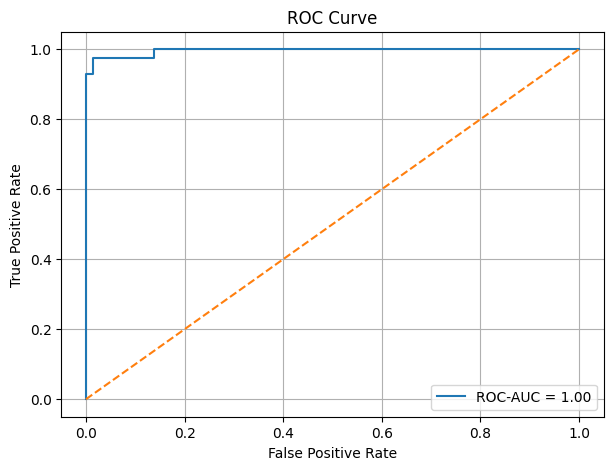

ROC-AUC Score: 0.996031746031746


In [ ]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.2f}')

plt.plot([0,1], [0,1], linestyle='--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()

plt.show()

print("ROC-AUC Score:", roc_auc)

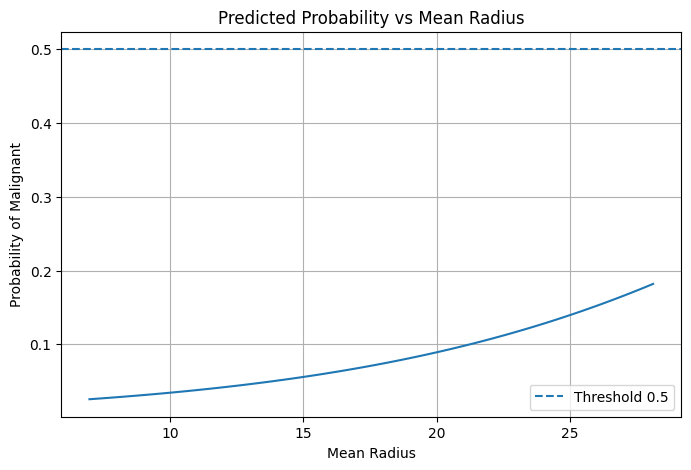

In [ ]:
feature = 'mean radius'

X_plot = pd.DataFrame(
    [X_train.median()] * 100
)

X_plot[feature] = np.linspace(
    X[feature].min(),
    X[feature].max(),
    100
)

X_plot_scaled = scaler.transform(X_plot)

probabilities = model.predict_proba(X_plot_scaled)[:, 1]

plt.figure(figsize=(8,5))

plt.plot(X_plot[feature], probabilities)

plt.axhline(y=0.5, linestyle='--', label='Threshold 0.5')

plt.title("Predicted Probability vs Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Probability of Malignant")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# Take one sample from the dataset
new_data = X.iloc[[0]]

# Apply the same scaling
new_data_scaled = scaler.transform(new_data)

# Predict probability
new_probability = model.predict_proba(new_data_scaled)[0][1]

# Predict class using threshold 0.5
new_prediction = int(new_probability >= 0.5)

print("Predicted Probability:", new_probability)

if new_prediction == 1:
    print("Prediction: Malignant")
else:
    print("Prediction: Benign")

Predicted Probability: 0.9999999806660215
Prediction: Malignant
